### From state-vector evolution to density-matrix dynamics

For an isolated system in a pure state, the Schrödinger equation is

$$
i\hbar\frac{d|\psi(t)\rangle}{dt}=H(t)|\psi(t)\rangle.
$$

Define the density matrix

$$
\rho(t)=|\psi(t)\rangle\langle\psi(t)|.
$$

Differentiating and using the Schrödinger equation and its adjoint gives

$$
\begin{aligned}
\dot\rho
&=|\dot\psi\rangle\langle\psi|
+|\psi\rangle\langle\dot\psi|\\
&=-\frac{i}{\hbar}H\rho+\frac{i}{\hbar}\rho H\\
&=-\frac{i}{\hbar}[H,\rho].
\end{aligned}
$$

This is the **von Neumann equation**. It also describes isolated
mixed states,

$$
\rho=\sum_a p_a|\psi_a\rangle\langle\psi_a|,
\qquad p_a\geq0,\qquad \sum_a p_a=1.
$$

Changing from a state vector to a density matrix does not itself
introduce an environment. In the present calculation, evolution
remains unitary.

### Annealing in the density-matrix representation

We retain the weighted three-spin Hamiltonian

$$
H(s)=(1-s)H_D+sH_P,
\qquad H_D=-\sum_{i=0}^{2}X_i,
$$

$$
H_P=-\frac12(I-Z_0Z_1)
-(I-Z_1Z_2)
-\frac32(I-Z_0Z_2).
$$

With energies in $E_0$, time in $\hbar/E_0$, and $s=t/T$,
the dimensionless evolution equation is

$$
\boxed{
\frac{d\rho}{ds}=-iT[H(s),\rho].
}
$$

The initial condition is

$$
\rho(0)=|\psi_0\rangle\langle\psi_0|,
\qquad
|\psi_0\rangle=|+\rangle^{\otimes3}.
$$

For three spins, $\rho$ is an $8\times8$ matrix. The solver
temporarily reshapes it into a vector of $64$ complex entries.

### Observables and validation

An observable $O$ has expectation value

$$
\langle O\rangle=\operatorname{Tr}(\rho O).
$$

In particular,

$$
P_{\mathrm{opt}}
=\rho_{001,001}+\rho_{110,110},
\qquad
\langle C\rangle=-\operatorname{Tr}(\rho H_P).
$$

The density matrix must satisfy

$$
\operatorname{Tr}\rho=1,\qquad
\rho=\rho^\dagger,\qquad
\rho\geq0.
$$

For our pure initial state, unitary evolution also preserves

$$
\operatorname{Tr}(\rho^2)=1.
$$

We validate the calculation by comparing its solution with the
independently evolved state vector:

$$
\rho(t)\approx|\psi(t)\rangle\langle\psi(t)|.
$$

### Subsequent open-system extension

For an open system, the reduced density matrix is

$$
\rho_S=\operatorname{Tr}_B(\rho_{SB}).
$$

Under a Markovian GKSL description, environmental effects are
included through a dissipator:

$$
\frac{d\rho}{dt}
=-i[H(t),\rho]+\mathcal D_t[\rho],
$$

$$
\mathcal D_t[\rho]
=\sum_\alpha\gamma_\alpha(t)
\left(
L_\alpha\rho L_\alpha^\dagger
-\frac12\{L_\alpha^\dagger L_\alpha,\rho\}
\right),
\qquad \gamma_\alpha(t)\geq0.
$$

Here all quantities use the same dimensionless units as above.
In the normalized ramp coordinate,

$$
\boxed{
\frac{d\rho}{ds}
=T\left(-i[H(s),\rho]+\mathcal D_s[\rho]\right).
}
$$

The current code sets $\mathcal D_s=0$. Dissipation will be
introduced after the unitary density-matrix calculation is verified.

Optimal bitstrings: 001, 110
Maximum cut: 5
Minimum problem energy: -5 E0
Initial trace: 1.000000
Initial purity: 1.000000

Final results
      T       P_opt         <C>      <H_P>/E0      E_res/E0
    0.1    0.251662    3.011623     -3.011623      1.988377
    1.0    0.379293    3.812571     -3.812571      1.187429
    5.0    0.794247    4.772839     -4.772839      0.227161
   10.0    0.950920    4.949907     -4.949907      0.050093
   20.0    0.998007    4.997705     -4.997705      0.002295
   50.0    0.999602    4.999561     -4.999561      0.000439

Numerical validation over the entire ramp
T=  0.1: trace error=3.33e-16, Hermiticity error=0.00e+00, purity error=7.75e-11, minimum eigenvalue=-6.18e-11, rho-reference error=1.51e-10
T=  1.0: trace error=3.33e-16, Hermiticity error=0.00e+00, purity error=4.95e-11, minimum eigenvalue=-6.34e-11, rho-reference error=2.83e-10
T=  5.0: trace error=4.44e-16, Hermiticity error=0.00e+00, purity error=1.19e-11, minimum eigenvalue=-1.32e-11, rho-r

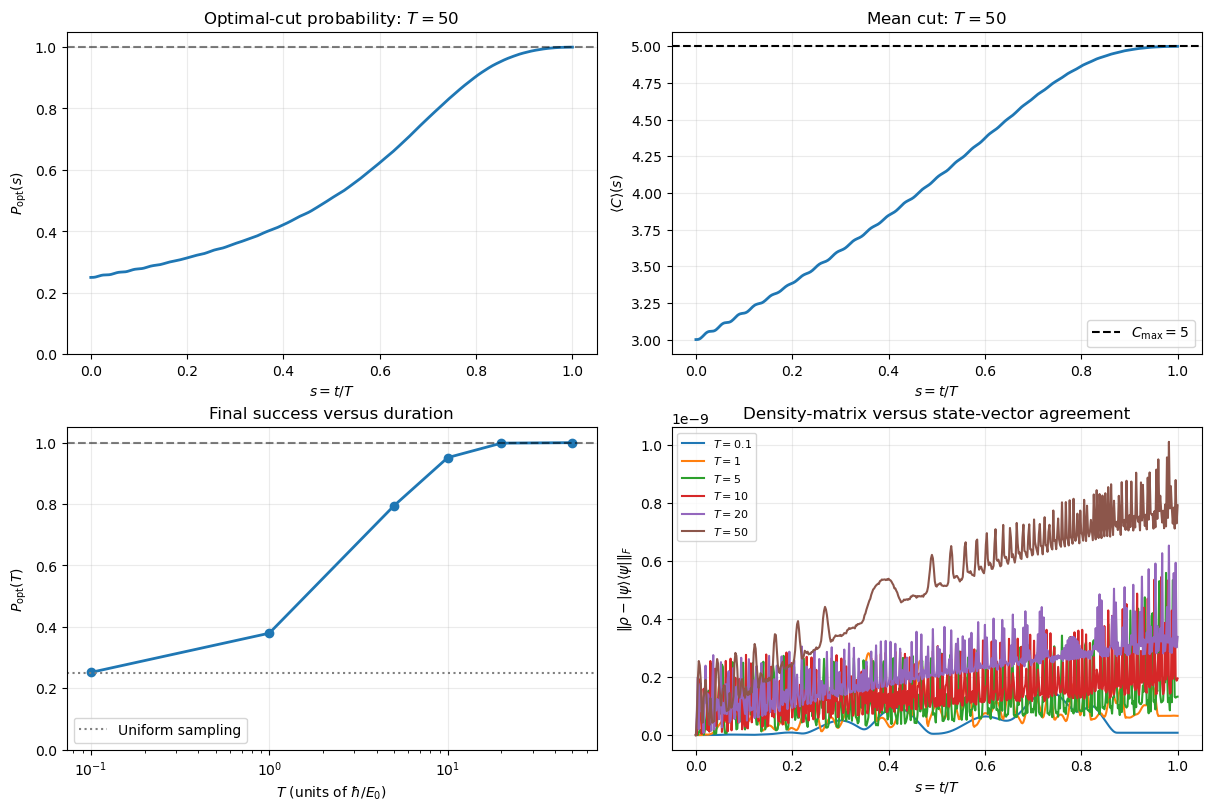

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. Parameters
# ============================================================
N = 3
dim = 2**N

# Weighted triangle; spin 0 is the leftmost bit.
edges = [(0, 1, 1.0), (1, 2, 2.0), (0, 2, 3.0)]

# Durations in hbar/E0; Hamiltonian coefficients in E0.
T_values = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]




T_plot = 50.0
s_grid = np.linspace(0.0, 1.0, 501)

basis_labels = np.array([
    format(n, f"0{N}b") for n in range(dim)
])

# ============================================================
# 2. Spin operators and Hamiltonians
# ============================================================
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
I_full = np.eye(dim, dtype=complex)


def local_operator(operator, site):
    result = np.array([[1.0]], dtype=complex)
    for j in range(N):
        result = np.kron(result, operator if j == site else I2)
    return result


X_ops = [local_operator(X, i) for i in range(N)]
Z_ops = [local_operator(Z, i) for i in range(N)]

H_driver = -sum(X_ops)
C_op = np.zeros((dim, dim), dtype=complex)

for i, j, weight in edges:
    C_op += weight / 2 * (I_full - Z_ops[i] @ Z_ops[j])

H_problem = -C_op
cut_values = np.diag(C_op).real
problem_energies = -cut_values

C_max = cut_values.max()
E_min = problem_energies.min()
optimal_mask = np.isclose(cut_values, C_max)


def hamiltonian(s):
    return (1.0 - s) * H_driver + s * H_problem


# ============================================================
# 3. Initial pure state and density matrix
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)
rho_initial = np.outer(psi_initial, psi_initial.conj())

print(f"Optimal bitstrings: {', '.join(basis_labels[optimal_mask])}")
print(f"Maximum cut: {C_max:g}")
print(f"Minimum problem energy: {E_min:g} E0")
print(f"Initial trace: {np.trace(rho_initial).real:.6f}")
print(f"Initial purity: {np.trace(rho_initial @ rho_initial).real:.6f}")

# ============================================================
# 4. Density-matrix evolution and state-vector reference
# ============================================================
def run_comparison(T):

    def density_rhs(s, rho_flat):
        rho = rho_flat.reshape(dim, dim)
        H = hamiltonian(s)

        # No dissipation: von Neumann equation.
        drho_ds = -1j * T * (H @ rho - rho @ H)

        return drho_ds.ravel()

    rho_solution = solve_ivp(
        density_rhs,
        (0.0, 1.0),
        rho_initial.ravel(),
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    def state_rhs(s, psi):
        return -1j * T * (hamiltonian(s) @ psi)

    psi_solution = solve_ivp(
        state_rhs,
        (0.0, 1.0),
        psi_initial,
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not rho_solution.success:
        raise RuntimeError(rho_solution.message)
    if not psi_solution.success:
        raise RuntimeError(psi_solution.message)

    # Shape: (number of times, dim, dim)
    rho_history = rho_solution.y.T.reshape(-1, dim, dim)

    # Independent reference: |psi><psi| at each time.
    psi_history = psi_solution.y
    rho_reference = np.einsum(
        "it,jt->tij", psi_history, psi_history.conj()
    )

    populations = np.diagonal(
        rho_history, axis1=1, axis2=2
    ).real

    P_opt = populations[:, optimal_mask].sum(axis=1)
    mean_cut = populations @ cut_values
    mean_problem_energy = populations @ problem_energies

    traces = np.trace(rho_history, axis1=1, axis2=2)
    purity = np.einsum(
        "tij,tji->t", rho_history, rho_history
    ).real

    hermitian_conjugate = rho_history.conj().transpose(0, 2, 1)

    hermiticity_error = np.linalg.norm(
        rho_history - hermitian_conjugate, axis=(1, 2)
    )

    # Symmetrization is used only for the eigenvalue diagnostic.
    rho_hermitian = (rho_history + hermitian_conjugate) / 2
    min_eigenvalues = np.linalg.eigvalsh(rho_hermitian)[:, 0]

    reference_error = np.linalg.norm(
        rho_history - rho_reference, axis=(1, 2)
    )

    return {
        "s": rho_solution.t,
        "rho": rho_history,
        "P_opt": P_opt,
        "mean_cut": mean_cut,
        "mean_problem_energy": mean_problem_energy,
        "residual_energy": mean_problem_energy[-1] - E_min,
        "purity": purity,
        "trace_error": np.max(np.abs(traces - 1.0)),
        "hermiticity_error": np.max(hermiticity_error),
        "min_eigenvalue": np.min(min_eigenvalues),
        "reference_error": reference_error,
    }


results = {T: run_comparison(T) for T in T_values}

# ============================================================
# 5. Final observables
# ============================================================
print("\nFinal results")
print(
    f"{'T':>7}"
    f"{'P_opt':>12}"
    f"{'<C>':>12}"
    f"{'<H_P>/E0':>14}"
    f"{'E_res/E0':>14}"
)

for T, result in results.items():
    print(
        f"{T:7.1f}"
        f"{result['P_opt'][-1]:12.6f}"
        f"{result['mean_cut'][-1]:12.6f}"
        f"{result['mean_problem_energy'][-1]:14.6f}"
        f"{result['residual_energy']:14.6f}"
    )

print("\nNumerical validation over the entire ramp")
for T, result in results.items():
    print(
        f"T={T:5.1f}: "
        f"trace error={result['trace_error']:.2e}, "
        f"Hermiticity error={result['hermiticity_error']:.2e}, "
        f"purity error={np.max(np.abs(result['purity'] - 1)):.2e}, "
        f"minimum eigenvalue={result['min_eigenvalue']:.2e}, "
        f"rho-reference error={result['reference_error'].max():.2e}"
    )

# ============================================================
# 6. Plots
# ============================================================
selected = results[T_plot]

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), constrained_layout=True
)

ax = axes[0, 0]
ax.plot(selected["s"], selected["P_opt"], lw=2)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$P_{\mathrm{opt}}(s)$",
    title=fr"Optimal-cut probability: $T={T_plot:g}$",
    ylim=(0, 1.05),
)

ax = axes[0, 1]
ax.plot(selected["s"], selected["mean_cut"], lw=2)
ax.axhline(
    C_max, color="black", ls="--",
    label=fr"$C_{{\max}}={C_max:g}$",
)
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\langle C\rangle(s)$",
    title=fr"Mean cut: $T={T_plot:g}$",
)
ax.legend()

ax = axes[1, 0]
ax.semilogx(
    T_values,
    [results[T]["P_opt"][-1] for T in T_values],
    "o-", lw=2,
)
ax.axhline(1.0, color="black", ls="--", alpha=0.5)
ax.axhline(
    optimal_mask.sum() / dim,
    color="gray", ls=":", label="Uniform sampling",
)
ax.set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$P_{\mathrm{opt}}(T)$",
    title="Final success versus duration",
    ylim=(0, 1.05),
)
ax.legend()

ax = axes[1, 1]
for T in T_values:
    ax.plot(
        results[T]["s"],
        results[T]["reference_error"],
        label=fr"$T={T:g}$",
    )
ax.set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\|\rho-|\psi\rangle\langle\psi|\|_F$",
    title="Density-matrix versus state-vector agreement",
)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.legend(fontsize=8)

for ax in axes.flat:
    ax.grid(alpha=0.25)

plt.show()

### Three-spin Max-Cut annealing with local dephasing

We retain the weighted triangle
$w_{01}=1$, $w_{12}=2$, $w_{02}=3$, with

$$
H(s)=(1-s)H_D+sH_P,\qquad
H_D=-\sum_{i=0}^{2}X_i,\qquad
H_P=-\sum_{(i,j)}\frac{w_{ij}}2(I-Z_iZ_j).
$$

Starting from $\rho(0)=|+++\rangle\langle+++|$, we integrate

$$
\frac{d\rho}{ds}
=T\left[-i[H(s),\rho]
+\gamma_\phi\sum_{i=0}^{2}(Z_i\rho Z_i-\rho)\right],
\qquad s=t/T.
$$

The jumps $L_i=Z_i$ describe independent computational-basis
dephasing, not thermal cooling. No bath degrees of freedom are
explicitly included in the $8\times8$ system density matrix.

Energies use units $E_0$, durations $\hbar/E_0$, and dephasing
coefficients $E_0/\hbar$. Under this convention, single-spin
coherence decays at rate $2\gamma_\phi$.

We compare optimal-cut probability, purity, and final residual energy:

$$
P_{\mathrm{opt}}=\rho_{001,001}+\rho_{110,110},
\qquad
\mathcal P=\operatorname{Tr}(\rho^2),
\qquad
E_{\mathrm{res}}=\operatorname{Tr}(H_P\rho(T))+5.
$$

The case $\gamma_\phi=0$ reproduces isolated evolution.

Optimal bitstrings: 001, 110
Maximum cut: 5
Minimum problem energy: -5 E0

Maximum isolated-reference observable discrepancy: 3.63e-09

    gamma      T       P_opt         <C>      <H_P>/E0      E_res/E0      Purity
        0    0.1    0.251662    3.011623     -3.011623      1.988377    1.000000
        0    1.0    0.379293    3.812571     -3.812571      1.187429    1.000000
        0    5.0    0.794247    4.772839     -4.772839      0.227161    1.000000
        0   10.0    0.950920    4.949907     -4.949907      0.050093    1.000000
        0   20.0    0.998007    4.997705     -4.997705      0.002295    1.000000
        0   50.0    0.999602    4.999561     -4.999561      0.000439    1.000000
    0.001    0.1    0.251662    3.011621     -3.011621      1.988379    0.999400
    0.001    1.0    0.379142    3.811725     -3.811725      1.188275    0.994024
    0.001    5.0    0.790511    4.766602     -4.766602      0.233398    0.970628
    0.001   10.0    0.940496    4.934758     -4.934758

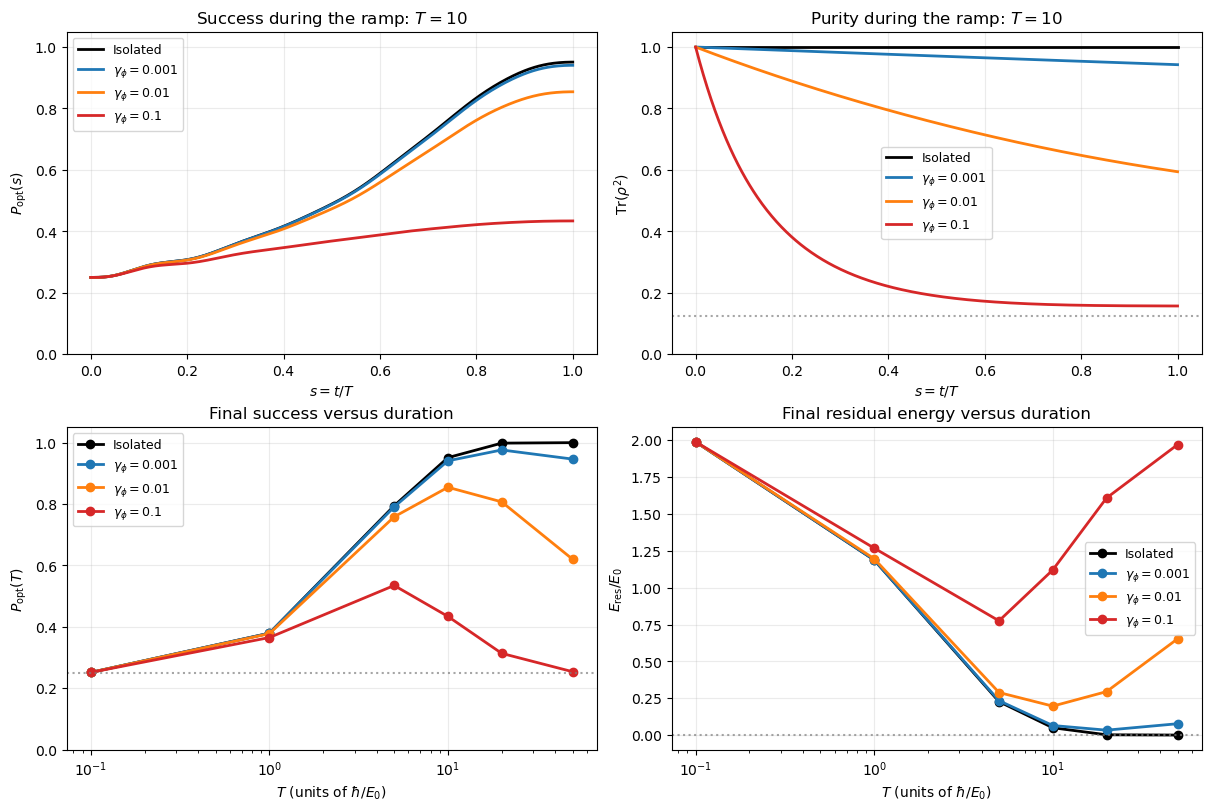

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ============================================================
# 1. Parameters
# ============================================================
N = 3
dim = 2**N

edges = [(0, 1, 1.0), (1, 2, 2.0), (0, 2, 3.0)]

T_values = [0.1, 1.0, 5.0, 10.0, 20.0, 50.0]
gamma_values = [0.0, 0.001, 0.01, 0.1]

T_plot = 10.0  # Duration used in the trajectory plots
s_grid = np.linspace(0.0, 1.0, 501)

# ============================================================
# 2. Operators and Hamiltonians
# ============================================================
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
I_full = np.eye(dim, dtype=complex)


def local_operator(operator, site):
    result = np.array([[1.0]], dtype=complex)
    for j in range(N):
        result = np.kron(result, operator if j == site else I2)
    return result


X_ops = [local_operator(X, i) for i in range(N)]
Z_ops = [local_operator(Z, i) for i in range(N)]

H_driver = -sum(X_ops)
C_op = np.zeros((dim, dim), dtype=complex)

for i, j, weight in edges:
    C_op += weight / 2 * (I_full - Z_ops[i] @ Z_ops[j])

H_problem = -C_op
cut_values = np.diag(C_op).real

C_max = cut_values.max()
E_min = -C_max
optimal_mask = np.isclose(cut_values, C_max)

basis_labels = np.array([
    format(n, f"0{N}b") for n in range(dim)
])


def hamiltonian(s):
    return (1.0 - s) * H_driver + s * H_problem


# ============================================================
# 3. Initial system density matrix
# ============================================================
psi_initial = np.ones(dim, dtype=complex) / np.sqrt(dim)
rho_initial = np.outer(psi_initial, psi_initial.conj())

print(f"Optimal bitstrings: {', '.join(basis_labels[optimal_mask])}")
print(f"Maximum cut: {C_max:g}")
print(f"Minimum problem energy: {E_min:g} E0")

# ============================================================
# 4. Local dephasing dissipator
# ============================================================
def dephasing_dissipator(rho, gamma_phi):
    dissipator = np.zeros_like(rho)

    for Zi in Z_ops:
        dissipator += gamma_phi * (Zi @ rho @ Zi - rho)

    return dissipator


# ============================================================
# 5. Integrate the master equation
# ============================================================
def run_annealing(T, gamma_phi):

    def rhs(s, rho_flat):
        rho = rho_flat.reshape(dim, dim)
        H = hamiltonian(s)

        coherent = -1j * (H @ rho - rho @ H)
        dissipative = dephasing_dissipator(rho, gamma_phi)

        return (T * (coherent + dissipative)).ravel()

    solution = solve_ivp(
        rhs,
        (0.0, 1.0),
        rho_initial.ravel(),
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    rho_history = solution.y.T.reshape(-1, dim, dim)

    # Use raw results without clipping eigenvalues or renormalizing.
    populations = np.diagonal(
        rho_history, axis1=1, axis2=2
    ).real

    P_opt = populations[:, optimal_mask].sum(axis=1)
    mean_cut = populations @ cut_values
    mean_energy = -mean_cut
    purity = np.einsum(
        "tij,tji->t", rho_history, rho_history
    ).real

    absolute_entries = np.abs(rho_history)
    coherence = (
        absolute_entries.sum(axis=(1, 2))
        - np.diagonal(
            absolute_entries, axis1=1, axis2=2
        ).sum(axis=1)
    )

    # Numerical diagnostics over the full trajectory
    traces = np.trace(rho_history, axis1=1, axis2=2)
    rho_dagger = rho_history.conj().transpose(0, 2, 1)

    trace_error = np.max(np.abs(traces - 1.0))
    hermiticity_error = np.max(
        np.linalg.norm(rho_history - rho_dagger, axis=(1, 2))
    )

    # Symmetrize only for the eigenvalue diagnostic.
    min_eigenvalue = np.linalg.eigvalsh(
        (rho_history + rho_dagger) / 2
    ).min()

    if (
        trace_error > 1e-7
        or hermiticity_error > 1e-7
        or min_eigenvalue < -1e-7
    ):
        raise RuntimeError(
            f"Numerical validation failed: T={T}, gamma={gamma_phi}"
        )

    return {
        "s": solution.t,
        "P_opt": P_opt,
        "mean_cut": mean_cut,
        "mean_energy": mean_energy,
        "residual_energy": mean_energy[-1] - E_min,
        "purity": purity,
        "coherence": coherence,
        "trace_error": trace_error,
        "hermiticity_error": hermiticity_error,
        "min_eigenvalue": min_eigenvalue,
    }


results = {
    (T, gamma): run_annealing(T, gamma)
    for gamma in gamma_values
    for T in T_values
}

# ============================================================
# 6. Verify gamma=0 against independent state-vector evolution
# ============================================================
max_unitary_error = 0.0

for T in T_values:
    reference = solve_ivp(
        lambda s, psi: -1j * T * (hamiltonian(s) @ psi),
        (0.0, 1.0),
        psi_initial,
        t_eval=s_grid,
        method="DOP853",
        rtol=1e-10,
        atol=1e-12,
    )

    if not reference.success:
        raise RuntimeError(reference.message)

    reference_probabilities = np.abs(reference.y)**2
    reference_success = reference_probabilities[optimal_mask].sum(axis=0)
    reference_cut = cut_values @ reference_probabilities

    unitary = results[(T, 0.0)]

    error = max(
        np.max(np.abs(unitary["P_opt"] - reference_success)),
        np.max(np.abs(unitary["mean_cut"] - reference_cut)),
    )
    max_unitary_error = max(max_unitary_error, error)

assert max_unitary_error < 1e-7

print(
    "\nMaximum isolated-reference observable discrepancy: "
    f"{max_unitary_error:.2e}"
)

# ============================================================
# 7. Final results
# ============================================================
print(
    f"\n{'gamma':>9}"
    f"{'T':>7}"
    f"{'P_opt':>12}"
    f"{'<C>':>12}"
    f"{'<H_P>/E0':>14}"
    f"{'E_res/E0':>14}"
    f"{'Purity':>12}"
)

for gamma in gamma_values:
    for T in T_values:
        result = results[(T, gamma)]
        print(
            f"{gamma:9.3g}"
            f"{T:7.1f}"
            f"{result['P_opt'][-1]:12.6f}"
            f"{result['mean_cut'][-1]:12.6f}"
            f"{result['mean_energy'][-1]:14.6f}"
            f"{result['residual_energy']:14.6f}"
            f"{result['purity'][-1]:12.6f}"
        )

print("\nWorst numerical diagnostics across all runs:")
print(
    "Trace error: "
    f"{max(r['trace_error'] for r in results.values()):.2e}"
)
print(
    "Hermiticity error: "
    f"{max(r['hermiticity_error'] for r in results.values()):.2e}"
)
print(
    "Minimum eigenvalue: "
    f"{min(r['min_eigenvalue'] for r in results.values()):.2e}"
)

# ============================================================
# 8. Four uncluttered comparison plots
# ============================================================
fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), constrained_layout=True
)

colors = ["black", "tab:blue", "tab:orange", "tab:red"]

for gamma, color in zip(gamma_values, colors):
    label = (
        "Isolated"
        if gamma == 0.0
        else fr"$\gamma_\phi={gamma:g}$"
    )
    selected = results[(T_plot, gamma)]

    axes[0, 0].plot(
        selected["s"], selected["P_opt"],
        color=color, lw=2, label=label,
    )

    axes[0, 1].plot(
        selected["s"], selected["purity"],
        color=color, lw=2, label=label,
    )

    axes[1, 0].semilogx(
        T_values,
        [results[(T, gamma)]["P_opt"][-1] for T in T_values],
        "o-", color=color, lw=2, label=label,
    )

    axes[1, 1].semilogx(
        T_values,
        [results[(T, gamma)]["residual_energy"] for T in T_values],
        "o-", color=color, lw=2, label=label,
    )

axes[0, 0].set(
    xlabel=r"$s=t/T$",
    ylabel=r"$P_{\mathrm{opt}}(s)$",
    title=fr"Success during the ramp: $T={T_plot:g}$",
    ylim=(0, 1.05),
)

axes[0, 1].axhline(
    1 / dim, color="gray", ls=":", alpha=0.7
)
axes[0, 1].set(
    xlabel=r"$s=t/T$",
    ylabel=r"$\operatorname{Tr}(\rho^2)$",
    title=fr"Purity during the ramp: $T={T_plot:g}$",
    ylim=(0, 1.05),
)

axes[1, 0].axhline(
    optimal_mask.sum() / dim,
    color="gray", ls=":", alpha=0.7,
)
axes[1, 0].set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$P_{\mathrm{opt}}(T)$",
    title="Final success versus duration",
    ylim=(0, 1.05),
)

axes[1, 1].axhline(
    0.0, color="gray", ls=":", alpha=0.7
)
axes[1, 1].set(
    xlabel=r"$T$ (units of $\hbar/E_0$)",
    ylabel=r"$E_{\mathrm{res}}/E_0$",
    title="Final residual energy versus duration",
)

for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

plt.show()